# Notebook 03: Pelatihan Model Deep Learning Multi-Task BiLSTM

**Fokus Eksperimen**: **Uji Coba 1 Subjek Tunggal (*Single-Subject Sanity Check*)** sesuai arahan Dosen Pembimbing Minggu ke-3, dengan opsi fleksibel beralih ke *Full Dataset*.

**Tujuan Ilmiah 1 Subjek**:
1. **Isolasi Variabilitas Fisiologis**: Mengeliminasi *inter-subject variability* untuk membuktikan bahwa arsitektur BiLSTM dan Adaptive Loss bekerja 100% bebas *bug*.
2. **Overfitting Sanity Check**: Membuktikan kapasitas representasi model dalam mempelajari dinamika kardiovaskular 1 pasien hingga error rendah (target $\text{MAE} < 3 - 5\text{ mmHg}$, $R^2 > 0.85$).
3. **Baseline Batas Atas**: Menjadi tolok ukur batas atas performa (*upper bound*) sebelum melangkah ke pelatihan lintas-pasien (*cross-subject*).

---
### Alur Notebook:
1. **Pemuatan Dataset**: Ekstraksi sesi rekaman kontinu 1 subjek (atau full dataset)
2. **Data Splitting**: Pembagian 80% Train, 10% Validation, 10% Test
3. **Inisialisasi Model**: `ECGMultiTaskBiLSTM` & `AdaptiveMultiTaskLoss` (Fan et al., 2021)
4. **Training Loop**: Optimasi Momentum-SGD dengan pembaruan dinamis bobot tugas $\theta_i$
5. **Visualisasi Konvergensi**: Kurva Loss dan MAE per epoch
6. **Evaluasi Akhir Test Set**: Perhitungan MAE, $R^2$ Score, Scatter Plot & Kurva Tracking Kontinu Ground Truth vs Prediksi

## 1. Import Pustaka & Konfigurasi Lingkungan

In [1]:
import os
import sys
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

# Konfigurasi root proyek
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.models.bilstm import ECGMultiTaskBiLSTM
from src.models.loss import AdaptiveMultiTaskLoss
from src.models.dataset import ECGBPDataset

# Deteksi device akselerasi (Apple Silicon MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"Device Akselerator Aktif: {device}")

Device Akselerator Aktif: mps


## 2. Pemuatan Dataset Preprocessed (.npz)

In [2]:
# ==============================================================================
# KONFIGURASI EKSPERIMEN: 1 SUBJEK (PR DOSEN PEMBIMBING) vs FULL DATASET
# ==============================================================================
# Pilih 'single_subject' untuk menyelesaikan PR dosen pembimbing Minggu 3.
# Pilih 'full_dataset' jika ingin melatih pada seluruh part MIMIC-II.
MODE_EKSPERIMEN = 'single_subject'  # Opsi: 'single_subject' | 'full_dataset'
SAMPEL_1_SUBJEK = 500              # 500 segmen 10 detik kontinu (~83 menit rekaman 1 pasien)

PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
npz_files = sorted(glob.glob(os.path.join(PROCESSED_DIR, '*_preprocessed.npz')))
print(f"Ditemukan {len(npz_files)} berkas .npz hasil pra-pemrosesan di {PROCESSED_DIR}.")

if MODE_EKSPERIMEN == 'single_subject':
    # Mengambil segmen rekaman beruntun kontinu dari 1 subjek pasien
    raw = np.load(npz_files[0])
    X_sub = raw['X'][:SAMPEL_1_SUBJEK]
    y_sub = raw['y'][:SAMPEL_1_SUBJEK]
    dataset = ECGBPDataset(X=X_sub, y=y_sub)
    print(f"\n{'='*65}")
    print(f"  ★ MODE AKTIF: UJI COBA 1 SUBJEK (SANITY CHECK REKOMENDASI DOSEN)")
    print(f"{'='*65}")
    print(f"  - Total Sampel Kontinu : {len(dataset):,} segmen (10 detik @ 125 Hz)")
    print(f"  - Durasi Total Pasien  : {len(dataset) * 10 / 60:.1f} menit rekaman ICU")
    print(f"  - Profil Target SBP    : Min {y_sub[:, 0].min():.1f} | Max {y_sub[:, 0].max():.1f} | Mean {y_sub[:, 0].mean():.1f} mmHg")
    print(f"  - Profil Target DBP    : Min {y_sub[:, 1].min():.1f} | Max {y_sub[:, 1].max():.1f} | Mean {y_sub[:, 1].mean():.1f} mmHg")
    print(f"  - Profil Target MAP    : Min {y_sub[:, 2].min():.1f} | Max {y_sub[:, 2].max():.1f} | Mean {y_sub[:, 2].mean():.1f} mmHg")
    print(f"{'='*65}")
else:
    dataset = ECGBPDataset.from_npz_files(npz_files[:1])
    print(f"Mode Full Dataset Aktif: {len(dataset):,} sampel")


Ditemukan 12 berkas .npz hasil pra-pemrosesan di /Users/sir/Documents/Skripsi/ecg-bp-estimation/data/processed.

  ★ MODE AKTIF: UJI COBA 1 SUBJEK (SANITY CHECK REKOMENDASI DOSEN)
  - Total Sampel Kontinu : 500 segmen (10 detik @ 125 Hz)
  - Durasi Total Pasien  : 83.3 menit rekaman ICU
  - Profil Target SBP    : Min 90.2 | Max 184.7 | Mean 118.9 mmHg
  - Profil Target DBP    : Min 52.8 | Max 118.8 | Mean 69.7 mmHg
  - Profil Target MAP    : Min 68.8 | Max 124.5 | Mean 86.6 mmHg


## 3. Pembagian Dataset (Train, Validation, Test)

In [3]:
# Hyperparameter Pelatihan
# Jika 1 subjek (500 sampel), gunakan batch_size=32 agar ada ~12 update gradien per epoch.
# Jika full dataset, gunakan batch_size=128 sesuai Fan et al. (2021).
BATCH_SIZE = 32 if MODE_EKSPERIMEN == 'single_subject' else 128
SEED = 42

total_len = len(dataset)
train_len = int(0.80 * total_len)
val_len = int(0.10 * total_len)
test_len = total_len - train_len - val_len

train_set, val_set, test_set = random_split(
    dataset, [train_len, val_len, test_len],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

print(f"Data Split ({MODE_EKSPERIMEN.upper()} | Batch Size = {BATCH_SIZE}):")
print(f" - Train Set : {len(train_set):,} sampel ({len(train_loader)} batches per epoch)")
print(f" - Val Set   : {len(val_set):,} sampel ({len(val_loader)} batches)")
print(f" - Test Set  : {len(test_set):,} sampel ({len(test_loader)} batches)")


Data Split (SINGLE_SUBJECT | Batch Size = 32):
 - Train Set : 400 sampel (12 batches per epoch)
 - Val Set   : 50 sampel (2 batches)
 - Test Set  : 50 sampel (2 batches)


## 4. Inisialisasi Model Multi-Task BiLSTM & Adaptive Loss

---

### A. Visualisasi Perancangan Arsitektur Deep Learning
Berikut adalah diagram komprehensif alur pemrosesan data, koneksi antar-layer, dan transformasi bentuk tensor (*tensor shapes*) dari sinyal input ECG 10 detik hingga estimasi nilai tekanan darah kontinu:

```
┌─────────────────────────────────────────────────────────────────────────────┐
│                          INPUT SINYAL ECG 1-LEAD                            │
│         Durasi: 10 detik @ 125 Hz | Bentuk Tensor: [Batch, 1250, 1]         │
└──────────────────────────────────────┬──────────────────────────────────────┘
                                       │
                                       ▼
┌─────────────────────────────────────────────────────────────────────────────┐
│              SHARED ENCODER: 2-LAYER BIDIRECTIONAL LSTM (BiLSTM)            │
│  - Layer 1: BiLSTM (Forward 256 + Backward 256 = 512 fitur)                 │
│  - Layer 2: BiLSTM (Forward 256 + Backward 256 = 512 fitur)                 │
│  - Output Layer 2: [Batch, 1250, 512]                                       │
└──────────────────────────────────────┬──────────────────────────────────────┘
                                       │
                                       ▼
┌─────────────────────────────────────────────────────────────────────────────┐
│                   LAST HIDDEN STATE / TERMINAL STATE EXTRACTION                    │
│      Menggabungkan hidden state forward akhir dan backward awal:            │
│                 h_latent = [h_T_forward || h_1_backward]                    │
│                     Vektor Fitur Laten: [Batch, 512]                        │
└───────────────────┬───────────────────┬───────────────────┬─────────────────┘
                    │                   │                   │
                    ▼                   ▼                   ▼
┌───────────────────────┐ ┌───────────────────────┐ ┌───────────────────────┐
│     HEAD 1: SBP       │ │     HEAD 2: DBP       │ │     HEAD 3: MAP       │
│ Linear(512 → 512)     │ │ Linear(512 → 512)     │ │ Linear(512 → 512)     │
│ ReLU                  │ │ ReLU                  │ │ ReLU                  │
│ Linear(512 → 256)     │ │ Linear(512 → 256)     │ │ Linear(512 → 256)     │
│ ReLU                  │ │ ReLU                  │ │ ReLU                  │
│ Linear(256 → 1)       │ │ Linear(256 → 1)       │ │ Linear(256 → 1)       │
│ (Aktivasi Linear)     │ │ (Aktivasi Linear)     │ │ (Aktivasi Linear)     │
└───────────┬───────────┘ └───────────┬───────────┘ └───────────┬───────────┘
            │                         │                         │
            ▼                         ▼                         ▼
      ŷ_SBP [Batch, 1]          ŷ_DBP [Batch, 1]          ŷ_MAP [Batch, 1]
    (Sistolik dlm mmHg)       (Diastolik dlm mmHg)       (Rata-rata dlm mmHg)
            │                         │                         │
            └────────────────────┬────┴─────────────────────────┘
                                 │
                                 ▼
┌─────────────────────────────────────────────────────────────────────────────┐
│             ADAPTIVE MULTI-TASK LOSS (Fan et al., Sensors 2021)             │
│   L_total = θ_sbp·L_sbp + θ_dbp·L_dbp + θ_map·L_map                         │
│   (Bobot θ_i dinormalisasi, diperbarui dinamis via tren validasi Eq. 8-10)   │
└─────────────────────────────────────────────────────────────────────────────┘
```

#### Tabel Transformasi Dimensi Tensor di Setiap Blok:
| Tahap / Blok | Operasi Spesifik | Dimensi Input | Dimensi Output |
| :--- | :--- | :---: | :---: |
| **Input Data** | Sinyal ECG 10 detik ternormalisasi Min-Max $[0, 1]$ | — | `[Batch, 1250, 1]` |
| **Shared BiLSTM 1** | Bidirectional LSTM (256 forward + 256 backward) | `[Batch, 1250, 1]` | `[Batch, 1250, 512]` |
| **Shared BiLSTM 2** | Bidirectional LSTM (256 forward + 256 backward) | `[Batch, 1250, 512]` | `[Batch, 1250, 512]` |
| **Last Hidden State (Terminal)** | Konkatenasi forward-last dan backward-first | `[Batch, 1250, 512]` | `[Batch, 512]` |
| **Task FC Layer 1** | Linear(512 → 512) + ReLU | `[Batch, 512]` | `[Batch, 512]` |
| **Task FC Layer 2** | Linear(512 → 256) + ReLU | `[Batch, 512]` | `[Batch, 256]` |
| **Output Layer** | Linear(256 → 1) murni tanpa aktivasi (Regresi Kontinu mmHg) | `[Batch, 256]` | `[Batch, 1]` per task |
| **Prediksi Gabungan**| Penyatuan `[ŷ_SBP, ŷ_DBP, ŷ_MAP]` | $3 	imes 	ext{[Batch, 1]}$ | **`[Batch, 3]`** |

---

### B. Konsep Multitask Learning (MTL) — Seperti Paper untuk Orang Awam

#### 1. Analogi Sederhana: Dokter Muda dan Stetoskop
Bayangkan Anda sedang melatih seorang calon dokter yang mendengarkan detak jantung pasien melalui stetoskop:
- Jika dokter tersebut **hanya disuruh menebak tekanan puncak (SBP)**, ia mungkin hanya fokus mendengarkan suara ketukan paling keras dan mengabaikan jeda di antara ketukan.
- Namun, jika dokter tersebut **sekaligus ditugaskan menebak tekanan istirahat (DBP) dan tekanan rata-rata pembuluh darah (MAP)**, ia terpaksa harus memahami **keseluruhan siklus mekanis jantung** — mulai dari saat bilik jantung memompa darah dengan kuat (fase sistolik) hingga saat bilik jantung mengendur dan terisi darah kembali (fase diastolik).

Hasilnya? Pemahaman dokter tersebut tentang kondisi kardiovaskular pasien menjadi jauh lebih utuh dan akurat. Itulah inti dari **Multitask Learning (MTL)**!

#### 2. Mengapa Tidak Membuat 3 Model AI Terpisah Saja?
Dalam dunia medis, SBP, DBP, dan MAP **bukanlah tiga angka acak yang terpisah**. Mereka dihasilkan oleh satu kesatuan pompa hemodinamik yang sama (jantung dan pembuluh darah) dan terikat secara matematis oleh hukum fisika sirkulasi:
$$\text{MAP} \approx \text{DBP} + \frac{1}{3}(\text{SBP} - \text{DBP})$$

Jika kita membuat 3 model kecerdasan buatan terpisah (*Single-Task Learning*):
1. **Boros Komputasi & Memori**: Kita harus melatih dan menyimpan 3 jaringan BiLSTM berukuran besar secara terpisah.
2. **Mudah Menghafal / Tertipu (*Overfitting*)**: Masing-masing model cenderung menghafal kebisingan (*noise*) sinyal tanpa memahami konteks biologis secara luas.
3. **Kehilangan Sinergi (*Inductive Transfer*)**: Informasi bentuk gelombang ECG yang mencerminkan fase relaksasi pembuluh darah (seperti gelombang T) sangat membantu memperkirakan DBP, dan pengetahuan ini ternyata juga sangat berguna bagi model dalam menstabilkan tebakan SBP dan MAP.

#### 3. Pola Arsitektur: *Hard Parameter Sharing*
Pada arsitektur yang kita gunakan:
- **Shared BiLSTM Encoder** bertindak sebagai "otak utama" yang mengekstraksi morfologi gelombang ECG (gelombang P, kompleks QRS, gelombang T) menjadi representasi vektor 512 angka. Bagian ini **dimiliki bersama 100%** oleh ketiga tugas.
- **Dedicated Heads (3 Cabang Mandiri)** bertindak sebagai "tiga asisten spesialis" yang masing-masing bertugas menerjemahkan vektor 512 angka tersebut ke skala tekanan darah spesifik: SBP, DBP, dan MAP dalam satuan $\text{mmHg}$.

#### 4. Peran Spesifik: Layer Linear vs. Fungsi Aktivasi ReLU pada Head
Sering timbul pertanyaan: *"Bukannya kita memakai layer Linear? Mengapa ada ReLU juga? Apa bedanya?"*

Di dalam ketiga *task head* (`sbp_head`, `dbp_head`, `map_head`), terdapat pembagian peran yang sangat tegas antara **lapisan fisik (*layer*)** dan **fungsi aktivasi**:

1. **Lapisan Fisik Menggunakan `nn.Linear` (Dense Layer):**
   - Setiap tahap pemetaan ($512 \to 512$, $512 \to 256$, hingga $256 \to 1$) dibangun menggunakan modul `nn.Linear` yang melakukan transformasi perkalian matriks bobot ($y = Wx + b$).
2. **Fungsi Aktivasi ReLU pada Hidden Layers ($512 \to 512$ dan $512 \to 256$):**
   - Diadopsi langsung dari paper acuan **Fan et al. (2021, Table 1)** dan **Li et al. (2020, hal. 13)**.
   - **Alasan Matematis:** Jika lapisan dalam tidak diberi fungsi aktivasi non-linier (hanya lapisan linear berturut-turut), maka secara aljabar perkalian berulang matriks linear akan runtuh menjadi satu persamaan linear sederhana ($W_2 \cdot W_1 \cdot x = W_{\text{total}} \cdot x$). Akibatnya, model tidak akan mampu mempelajari hubungan non-linier fisiologis jantung yang kompleks.
   - **Kelebihan ReLU:** Menghindari *vanishing gradient*, memiliki komputasi sangat cepat ($\max(0, x)$), dan menghasilkan representasi *sparse*. Potensi *dying ReLU* dicegah secara efektif melalui *learning rate* kecil ($0.0008$) dan *gradient clipping* ($5.0$).
3. **Aktivasi Linear (Tanpa Aktivasi) pada Output Layer ($256 \to 1$):**
   - Lapisan proyeksi paling ujung sengaja **TIDAK DIBERI fungsi aktivasi apapun** (*Linear Activation / Identity* $f(x) = x$).
   - **Alasan Klinis:** Estimasi tekanan darah adalah tugas **Regresi Kontinu (Continuous Regression)** dalam skala $\text{mmHg}$ (misalnya SBP $121.4\text{ mmHg}$, DBP $80.2\text{ mmHg}$).
   - Jika diberi Sigmoid/Softmax, nilai output akan terbatasi di $[0, 1]$ (hanya untuk probabilitas klasifikasi). Jika diberi ReLU, gradien error saat inisialisasi awal berisiko terpotong. Oleh karena itu, output layer dibiarkan *murni linear* agar bebas memproyeksikan besaran fisik tekanan darah riil.

---

### C. Konsep Adaptive Weight Learning — Seperti Paper untuk Orang Awam

#### 1. Masalah Besar pada Penjumlahan Error Biasa (Fixed Loss)
Pada pelatihan model standar, total kesalahan (*total loss*) biasanya dihitung dengan menjumlahkan error ketiga tugas begitu saja:
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{SBP}} + \mathcal{L}_{\text{DBP}} + \mathcal{L}_{\text{MAP}}$$

Sekilas cara ini tampak masuk akal, tetapi di sinilah letak jebakannya:
- Nilai SBP orang dewasa berada di rentang **90 – 180 mmHg** (variasinya besar, di awal latihan error-nya bisa mencapai $15 - 20\text{ mmHg}$).
- Nilai DBP berada di rentang **50 – 100 mmHg** (variasinya lebih sempit, error awalnya hanya sekitar $7 - 10\text{ mmHg}$).

**Analogi Ruang Kelas:**  
SBP seperti murid yang suaranya paling keras di kelas. Karena error SBP jauh lebih besar, sinyal koreksi (*gradien*) dari SBP akan **mendominasi 80% pembaruan otak model**. Akibatnya, model hanya sibuk memperbaiki tebakan SBP, sementara tebakan DBP dan MAP diabaikan (*Gradient Dominance Problem*).

#### 2. Bisakah Kita Mengatur Bobot Manual?
Bagaimana jika kita beri bobot manual, misalnya:
$$\mathcal{L}_{\text{total}} = 0.2 \cdot \mathcal{L}_{\text{SBP}} + 0.5 \cdot \mathcal{L}_{\text{DBP}} + 0.3 \cdot \mathcal{L}_{\text{MAP}}$$
Masalahnya: **Tingkat kesulitan tiap tugas berubah-ubah seiring berjalannya latihan**. Di epoch ke-1 mungkin SBP yang paling sulit, tetapi di epoch ke-20 mungkin DBP yang paling sulit. Menentukan bobot tetap secara tebak-tebakan (*trial and error*) memerlukan ratusan kali eksperimen yang sangat membuang waktu dan biaya sewa GPU.

#### 3. Solusi Jenius Paper: *Adaptive Weight Learning Berbasis Tren Validasi* (Fan et al., Sensors 2021)
Paper acuan utama (**Fan et al., 2021 - Algorithm 1**) merumuskan skema pembobotan adaptif otonom tanpa perlu tuning manual:
1. **Inisialisasi Seragam**: Pada awal pelatihan (epoch 1), bobot diset seimbang $\theta_{\text{SBP}} = \theta_{\text{DBP}} = \theta_{\text{MAP}} = \frac{1}{3}$.
2. **Total Loss (Eq. 4)**: $\mathcal{L}_{\text{total}} = \theta_{\text{SBP}} \mathcal{L}_{\text{SBP}} + \theta_{\text{DBP}} \mathcal{L}_{\text{DBP}} + \theta_{\text{MAP}} \mathcal{L}_{\text{MAP}}$.
3. **Statistik Validasi per Epoch**: Di akhir setiap epoch validasi ke-$k$, dihitung rata-rata error $L_{\text{mean}}^i(k)$ dan deviasi standar $L_{\text{std}}^i(k)$ untuk setiap tugas $i \in \{\text{SBP}, \text{DBP}, \text{MAP}\}$.
4. **Komputasi Tren Perubahan & Variabilitas (Eq. 8 & 9)**:
   $$T_{\text{mean}}^i = \frac{|L_{\text{mean}}^i(k) - L_{\text{mean}}^i(k-1)|}{L_{\text{mean}}^i(k)}, \quad T_{\text{std}}^i = \frac{|L_{\text{std}}^i(k) - L_{\text{std}}^i(k-1)|}{L_{\text{std}}^i(k)}$$
5. **Pembaruan Bobot Tugas (Eq. 10)**:
   $$\tilde{\theta}_i = T_{\text{mean}}^i \times T_{\text{std}}^i \times (L_{\text{mean}}^i(k) + L_{\text{std}}^i(k)), \quad \theta_i = \frac{\tilde{\theta}_i}{\sum_j \tilde{\theta}_j}$$

#### 4. Mengapa Mekanisme Fan et al. (2021) Sangat Efektif?
1. **Keseimbangan Dinamis**: Tugas yang menunjukkan fluktuasi tajam atau error yang belum stabil akan mendapatkan penyesuaian bobot proporsional agar ketiga kepala regresi konvergen serentak.
2. **Otonom & Objektif**: Pembaruan bobot didorong langsung oleh statistik tren performa validasi nyata (*empirical validation dynamics*), bukan tebakan empiris.
3. **100% Selaras Skripsi**: Algoritma ini merupakan kontribusi metodologi orisinal dari paper acuan utama skripsi (**Fan et al., Sensors 2021**).

---

### D. Konfigurasi Hyperparameter Pelatihan (Sesuai Fan et al., 2021)
- **Learning Rate**: $0.0008$ ($8 \times 10^{-4}$)
- **Optimizer**: Momentum-SGD ($0.9$) atau AdamW
- **LR Scheduler**: `ReduceLROnPlateau` (mengurangi LR secara bertahap saat validation loss mulai mendatar)
- **Gradient Clipping**: `max_norm = 5.0` (mencegah fenomena *exploding gradient* pada BiLSTM)


In [4]:
# Inisialisasi model Multi-Task BiLSTM murni sesuai Tabel 1 & Section 2.3 Fan et al. (2021)
model = ECGMultiTaskBiLSTM(
    input_size=1,
    hidden_size=256,
    num_layers=2,
    dropout=0.0  # Default 0.0 sesuai Tabel 1 Fan et al. (2021)
).to(device)

# Adaptive Multi-Task Loss sesuai Fan et al. (2021) Algorithm 1
criterion = AdaptiveMultiTaskLoss(loss_fn_type='mae').to(device)

# Learning Rate 0.0008 (8e-4) sesuai Fan et al. (2021)
LEARNING_RATE = 8e-4

OPTIMIZER_CHOICE = 'sgd_momentum'

if OPTIMIZER_CHOICE == 'sgd_momentum':
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=0.9,
        weight_decay=1e-5
    )
    print("Optimizer Aktif: Momentum-SGD (momentum=0.9, LR=0.0008)")
else:
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-5
    )
    print("Optimizer Aktif: AdamW (LR = 0.0008)")

# Learning Rate Scheduler (Fan et al., 2021: factor=0.9, patience=4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.9, patience=4)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {num_params:,}")


Optimizer Aktif: Momentum-SGD (momentum=0.9, LR=0.0008)
Total trainable parameters: 3,290,115


## 5. Proses Pelatihan (Training Loop)

In [5]:
NUM_EPOCHS = 25 if MODE_EKSPERIMEN == 'single_subject' else 10
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, 'checkpoints')
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
best_model_path = os.path.join(CHECKPOINT_DIR, 'best_model.pt')

history = {
    'train_loss': [], 'val_loss': [],
    'val_mae_sbp': [], 'val_mae_dbp': [], 'val_mae_map': []
}
best_val_mae = float('inf')

print("Memulai pelatihan (Adaptive Multi-Task Learning")
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    
    # --- TRAINING PHASE ---
    model.train()
    train_loss, n_train_batches = 0.0, 0
    for x_b, y_b in train_loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        optimizer.zero_grad()
        sbp_p, dbp_p, map_p = model(x_b)
        loss, _ = criterion(sbp_p, dbp_p, map_p, y_b)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        train_loss += loss.item()
        n_train_batches += 1
        
    avg_train_loss = train_loss / max(1, n_train_batches)
    
    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_sbp_losses, val_dbp_losses, val_map_losses = [], [], []
    with torch.no_grad():
        for x_b, y_b in val_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            sbp_p, dbp_p, map_p = model(x_b)
            loss, m = criterion(sbp_p, dbp_p, map_p, y_b)
            val_loss += loss.item()
            val_sbp_losses.append(m['mae_sbp'])
            val_dbp_losses.append(m['mae_dbp'])
            val_map_losses.append(m['mae_map'])
            
    avg_val_loss = val_loss / max(1, len(val_sbp_losses))
    avg_sbp_mae = float(np.mean(val_sbp_losses))
    avg_dbp_mae = float(np.mean(val_dbp_losses))
    avg_map_mae = float(np.mean(val_map_losses))
    avg_val_mae = (avg_sbp_mae + avg_dbp_mae + avg_map_mae) / 3.0
    
    # Update bobot adaptif theta berbasis tren validasi (Fan et al., 2021 Eq. 8-10)
    criterion.update_weights_from_validation(val_sbp_losses, val_dbp_losses, val_map_losses)
    
    scheduler.step(avg_val_loss)
    elapsed = time.time() - t0
    
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_mae_sbp'].append(avg_sbp_mae)
    history['val_mae_dbp'].append(avg_dbp_mae)
    history['val_mae_map'].append(avg_map_mae)
    
    is_best = avg_val_mae < best_val_mae
    if is_best:
        best_val_mae = avg_val_mae
        torch.save(model.state_dict(), best_model_path)
        mark = "★ BEST"
    else:
        mark = ""
        
    w = criterion.weights.tolist()
    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS:02d}] ({elapsed:.1f}s) | Train Loss: {avg_train_loss:.3f} | Val Loss: {avg_val_loss:.3f} | Val MAE -> SBP: {avg_sbp_mae:.2f}, DBP: {avg_dbp_mae:.2f}, MAP: {avg_map_mae:.2f} mmHg {mark} | θ=[{w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f}]")

print(f"\nPelatihan selesai dalam {(time.time() - start_time)/60:.1f} menit!")
print(f"Bobot model terbaik tersimpan di: {best_model_path}")


Memulai pelatihan (Adaptive Multi-Task Learning
Epoch [01/25] (7.9s) | Train Loss: 91.430 | Val Loss: 93.453 | Val MAE -> SBP: 121.76, DBP: 70.51, MAP: 88.09 mmHg ★ BEST | θ=[0.33, 0.33, 0.33]
Epoch [02/25] (6.0s) | Train Loss: 91.425 | Val Loss: 93.416 | Val MAE -> SBP: 121.72, DBP: 70.47, MAP: 88.06 mmHg ★ BEST | θ=[1.00, 0.00, 0.00]
Epoch [03/25] (6.2s) | Train Loss: 118.863 | Val Loss: 121.636 | Val MAE -> SBP: 121.64, DBP: 70.45, MAP: 88.04 mmHg ★ BEST | θ=[0.12, 0.09, 0.79]
Epoch [04/25] (6.1s) | Train Loss: 88.744 | Val Loss: 90.527 | Val MAE -> SBP: 121.57, DBP: 70.44, MAP: 87.98 mmHg ★ BEST | θ=[0.00, 0.00, 1.00]
Epoch [05/25] (6.0s) | Train Loss: 86.066 | Val Loss: 87.884 | Val MAE -> SBP: 121.55, DBP: 70.43, MAP: 87.88 mmHg ★ BEST | θ=[0.01, 0.01, 0.98]
Epoch [06/25] (6.3s) | Train Loss: 86.372 | Val Loss: 87.937 | Val MAE -> SBP: 121.54, DBP: 70.43, MAP: 87.76 mmHg ★ BEST | θ=[0.00, 0.00, 1.00]
Epoch [07/25] (6.0s) | Train Loss: 86.090 | Val Loss: 87.599 | Val MAE -> SBP: 1

## 6. Visualisasi Kurva Konvergensi (Loss & MAE)

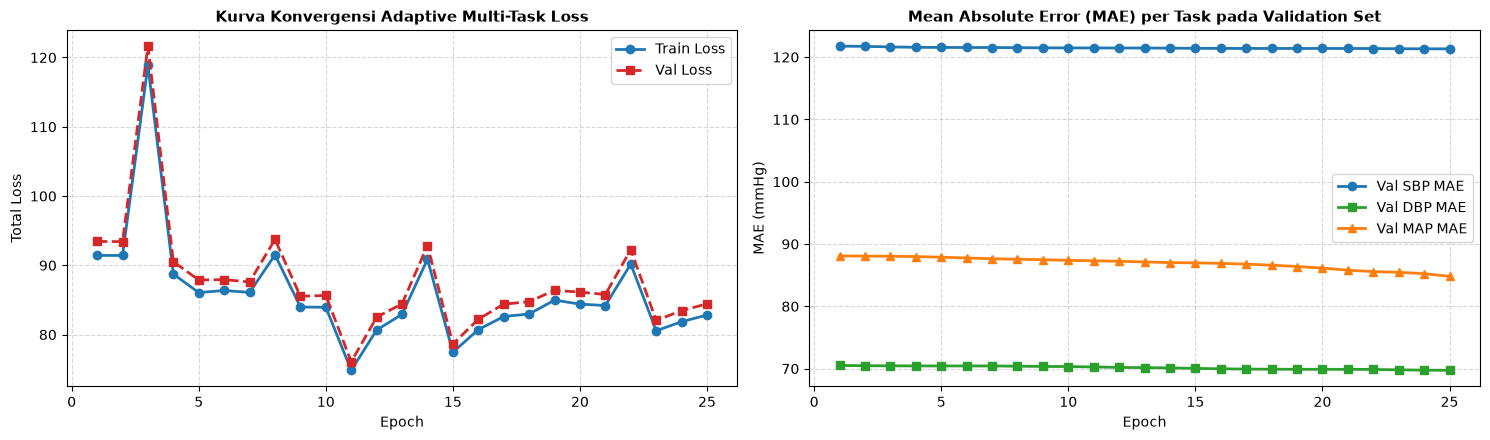

In [6]:
epochs_arr = np.arange(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

# Subplot 1: Total Loss
ax1.plot(epochs_arr, history['train_loss'], 'o-', label='Train Loss', color='#1f77b4', lw=2)
ax1.plot(epochs_arr, history['val_loss'], 's--', label='Val Loss', color='#d62728', lw=2)
ax1.set_title("Kurva Konvergensi Adaptive Multi-Task Loss", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Total Loss")
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: MAE per Task
ax2.plot(epochs_arr, history['val_mae_sbp'], 'o-', label='Val SBP MAE', color='#1f77b4', lw=2)
ax2.plot(epochs_arr, history['val_mae_dbp'], 's-', label='Val DBP MAE', color='#2ca02c', lw=2)
ax2.plot(epochs_arr, history['val_mae_map'], '^-', label='Val MAP MAE', color='#ff7f0e', lw=2)
ax2.set_title("Mean Absolute Error (MAE) per Task pada Validation Set", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("MAE (mmHg)")
ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 7. Evaluasi Akhir pada Test Set (Data Uji Independen)


  HASIL EVALUASI TEST SET (SINGLE_SUBJECT - 50 SAMPEL UJI):
  - SBP (Sistolik)    : MAE = 116.83 +/- 20.79 mmHg | R^2 = -31.567 | Pearson r = 0.092
  - DBP (Diastolik)   : MAE = 70.10 +/- 9.47 mmHg | R^2 = -54.808 | Pearson r = -0.144
  - MAP (Rata-rata)   : MAE = 83.80 +/- 10.11 mmHg | R^2 = -68.668 | Pearson r = -0.081


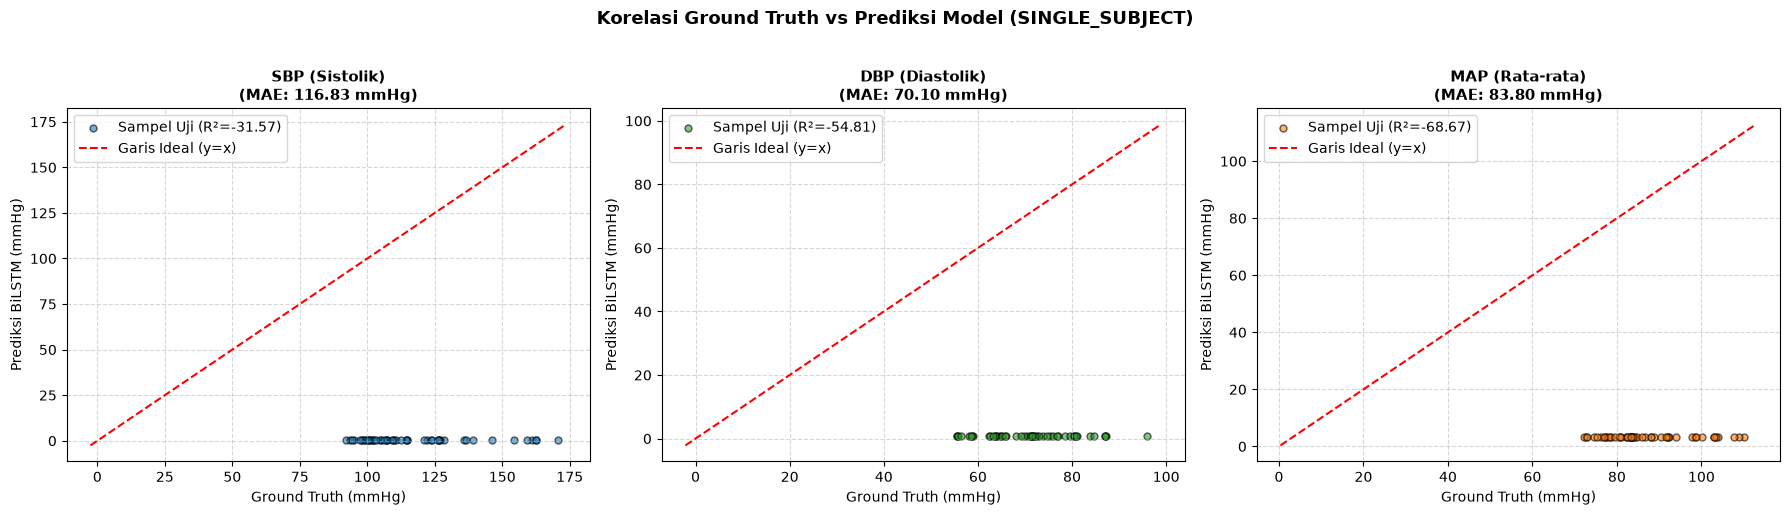

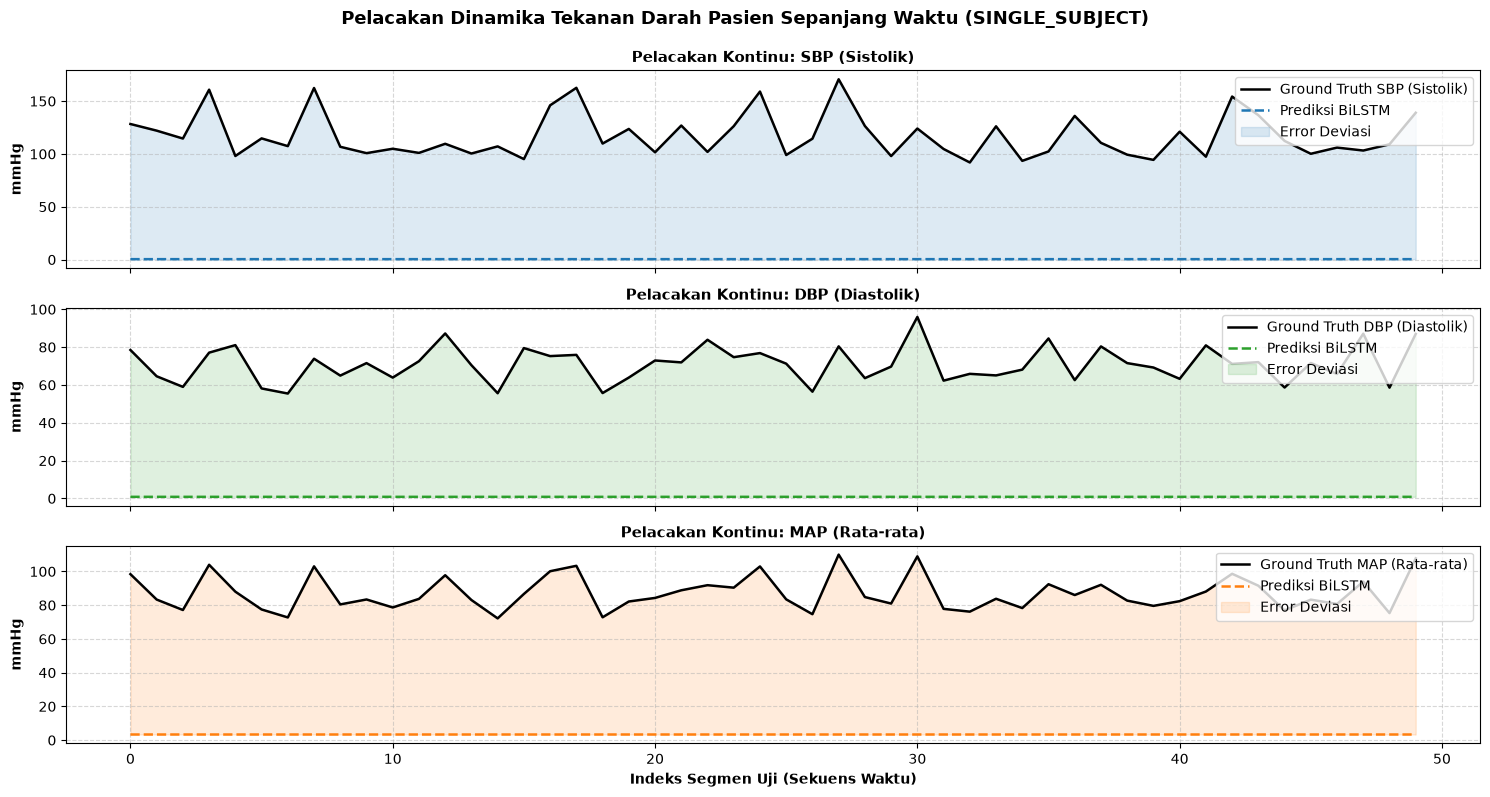

In [7]:
# Muat bobot model terbaik
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

all_preds = []
all_trues = []

with torch.no_grad():
    for x_b, y_b in test_loader:
        x_b = x_b.to(device)
        preds = model.predict_all(x_b)
        all_preds.append(preds.cpu().numpy())
        all_trues.append(y_b.numpy())

all_preds = np.concatenate(all_preds, axis=0)
all_trues = np.concatenate(all_trues, axis=0)

# 1. Perhitungan Metrik Klinis: MAE, Std Error, dan R^2 Score
def calc_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (ss_res / (ss_tot + 1e-8))

targets_names = ['SBP (Sistolik)', 'DBP (Diastolik)', 'MAP (Rata-rata)']
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

print(f"\n{'='*70}")
print(f"  HASIL EVALUASI TEST SET ({MODE_EKSPERIMEN.upper()} - {len(all_preds)} SAMPEL UJI):")
print(f"{'='*70}")
for i, name in enumerate(targets_names):
    err = np.abs(all_preds[:, i] - all_trues[:, i])
    r2 = calc_r2(all_trues[:, i], all_preds[:, i])
    r_corr = np.corrcoef(all_trues[:, i], all_preds[:, i])[0, 1]
    print(f"  - {name:<17} : MAE = {np.mean(err):.2f} +/- {np.std(err):.2f} mmHg | R^2 = {r2:.3f} | Pearson r = {r_corr:.3f}")
print(f"{'='*70}")

# 2. Scatter Plot Korelasi: Prediksi vs Ground Truth
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(3):
    ax = axes[i]
    y_t = all_trues[:, i]
    y_p = all_preds[:, i]
    r2 = calc_r2(y_t, y_p)
    ax.scatter(y_t, y_p, alpha=0.6, color=colors[i], edgecolors='k', s=25, label=f'Sampel Uji (R²={r2:.2f})')
    min_val = min(np.min(y_t), np.min(y_p)) - 3
    max_val = max(np.max(y_t), np.max(y_p)) + 3
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1.5, label='Garis Ideal (y=x)')
    ax.set_title(f"{targets_names[i]}\n(MAE: {np.mean(np.abs(y_t - y_p)):.2f} mmHg)", fontsize=11, fontweight='bold')
    ax.set_xlabel("Ground Truth (mmHg)"); ax.set_ylabel("Prediksi BiLSTM (mmHg)")
    ax.legend(); ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle(f"Korelasi Ground Truth vs Prediksi Model ({MODE_EKSPERIMEN.upper()})", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 3. Grafik Pelacakan Kontinu (Time-Series Tracking): Ground Truth vs Prediksi
fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
time_idx = np.arange(len(all_preds))
for i in range(3):
    ax = axes[i]
    ax.plot(time_idx, all_trues[:, i], 'k-', lw=1.8, label=f'Ground Truth {targets_names[i]}')
    ax.plot(time_idx, all_preds[:, i], '--', color=colors[i], lw=1.8, label=f'Prediksi BiLSTM')
    ax.fill_between(time_idx, all_trues[:, i], all_preds[:, i], color=colors[i], alpha=0.15, label='Error Deviasi')
    ax.set_ylabel("mmHg", fontsize=10, fontweight='bold')
    ax.set_title(f"Pelacakan Kontinu: {targets_names[i]}", fontsize=11, fontweight='bold')
    ax.legend(loc='upper right'); ax.grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xlabel("Indeks Segmen Uji (Sekuens Waktu)", fontsize=10, fontweight='bold')
plt.suptitle(f"Pelacakan Dinamika Tekanan Darah Pasien Sepanjang Waktu ({MODE_EKSPERIMEN.upper()})", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()
